[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DigitalPasts/alpcourse/blob/main/notebooks/05_Vector_Space_Model.ipynb)

# Woruldende: Eschatological Vocabulary in Old English Homilies

This notebook applies the vector space model approach described by
[Karsdorp et al. in "Exploring Texts using the Vector Space Model"](https://www.humanitiesdataanalysis.org/vector-space-model/notebook.html)
to a corpus of Old English homilies. The original notebook was developed
by Avital Romach for Akkadian and Egyptian corpora; this version was
substantially rewritten and adapted for Old English eschatological texts
as part of the Woruldende project.

By representing texts as numeric vectors capturing word frequencies, we
quantify lexical similarities and differences between three author groups:
Wulfstan of York, Ælfric of Eynsham, and the anonymous Blickling and
Vercelli homilists. The vector space model allows us to reason about texts
spatially, applying geometric concepts like cosine distance to assess how
"close" texts are based on shared vocabulary.

Texts are preprocessed by tokenizing, lowercasing, and normalising word
forms with a small hand-built dictionary (the `cf` column of the CSV
files), which merges the inflected forms of a limited set of high-frequency
words (e.g. `god`, `gode`, `godes` → `god`); all other words remain as
lowercased surface forms. The ECHOE XML itself contains no lemma
annotation, and the same dictionary was applied to all 19 texts, including
the Ælfric texts taken from Thorpe (1844) via Wikisource. One manual
normalisation is applied on top: `dryhten` → `drihten`, merging a Vercelli
spelling variant with the more common `drihten`. A TF-IDF document-term
matrix is then constructed. We then apply cosine distance measurement and
t-SNE visualisation to explore stylistic patterns across the corpus.
Control analyses (surface forms only; orthography harmonised across
editions; robustness to vocabulary size, random seed, and the removal of
individual texts) are at the end of the notebook.

This notebook was adapted and developed by [Anonymous for review], with
methodological guidance from Shai Gordin and Eliese-Sophie Lincke
(co-authors). It should be cited accordingly (see citation information
at the bottom).

Note: author names will be restored in the final published version.

# Preprocessing the corpus

## Imports

In [2]:
# ================================================================
# WORULDENDE — Notebook 5 Replacement Data v3
# 19 texts — expanded corpus
# ================================================================

import os
import pandas as pd
from google.colab import files

# ── STEP 1: UPLOAD YOUR FILES ────────────────────────────────
# Upload ALL of the following files at once:
#   - woruldende_metadata_v3.csv
#   - WHom_SermoLupi_A.csv, WHom_SermoLupi_B.csv
#   - WHom_Antichrist.csv, WHom_SignsDoom.csv
#   - BlHom_II.csv, BlHom_IV.csv, BlHom_V.csv
#   - BlHom_VII.csv, BlHom_X.csv, BlHom_XI.csv
#   - VHom_II.csv, VHom_IV.csv, VHom_V.csv, VHom_IX.csv
#   - BHH_CCCC303.csv
#   - AECHom_I.csv, AECHom_XV.csv, AECHom_XXI.csv, AECHom_XL.csv

uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

# ── STEP 2: LOAD METADATA ────────────────────────────────────
metadata = pd.read_csv("woruldende_metadata_v3.csv", encoding="utf-8", index_col="text_id").fillna("")
print("\nMetadata loaded:")
print(metadata)

# ── STEP 3: LOAD CORPUS ──────────────────────────────────────
text_order = [
    "WHom_SermoLupi_A", "WHom_SermoLupi_B", "WHom_Antichrist", "WHom_SignsDoom",
    "BlHom_II", "BlHom_IV", "BlHom_V", "BlHom_VII", "BlHom_X", "BlHom_XI",
    "VHom_II", "VHom_IV", "VHom_V", "VHom_IX",
    "BHH_CCCC303",
    "AECHom_I", "AECHom_XV", "AECHom_XXI", "AECHom_XL"
]

corpus = []
for text_id in text_order:
    filename = f"{text_id}.csv"
    if filename in uploaded or os.path.exists(filename):
        df = pd.read_csv(filename, encoding="utf-8").fillna("")
        corpus.append(df)
        print(f"  Loaded {filename}: {len(df)} rows")
    else:
        print(f"  WARNING: {filename} not found!")

print(f"\nCorpus loaded: {len(corpus)} texts")

# ── STEP 4: PATCH FUNCTIONS ──────────────────────────────────
def get_lemmatized_texts(corpus, break_perc=1, mask=True):
    texts_dict = {}
    for df in corpus:
        key = df["text"].iloc[0]
        words = df["cf"].replace("", "UNK").tolist() if "cf" in df.columns else df["norm"].replace("", "UNK").tolist()
        text = " ".join(str(w) for w in words if w)
        text_length_full = len(words)
        text_length_partial = sum(1 for w in words if w not in ["UNK", "X", ""])
        texts_dict[key] = (text, text_length_full, text_length_partial)
    return texts_dict

def get_normalized_texts(corpus, break_perc=1, mask=True):
    texts_dict = {}
    for df in corpus:
        key = df["text"].iloc[0]
        words = df["norm"].replace("", "UNK").tolist()
        text = " ".join(str(w) for w in words if w)
        text_length_full = len(words)
        text_length_partial = sum(1 for w in words if w not in ["UNK", "X", ""])
        texts_dict[key] = (text, text_length_full, text_length_partial)
    return texts_dict

def get_segmented_unicode_texts(corpus, break_perc=1, mask=True):
    texts_dict = {}
    for df in corpus:
        key = df["text"].iloc[0]
        words = df["unicode_word"].replace("", "UNK").tolist()
        text = " ".join(str(w) for w in words if w)
        text_length_full = len(words)
        text_length_partial = sum(1 for w in words if w not in ["UNK", "X", ""])
        texts_dict[key] = (text, text_length_full, text_length_partial)
    return texts_dict

from sklearn.feature_extraction.text import TfidfVectorizer

def vectorize(corpus, analyzer="word", ngram_range=(1,1), max_df=1.0, min_df=1, max_features=None, stop_words=["UNK", "X"]):
    vectorizer = TfidfVectorizer(
        input="content", lowercase=True, analyzer=analyzer,
        token_pattern=r"(?u)\b\w+\b",
        ngram_range=ngram_range,
        max_df=max_df, min_df=min_df,
        max_features=max_features,
        stop_words=stop_words
    )
    counts = vectorizer.fit_transform(corpus["text"].tolist()).toarray()
    stop_words_out = vectorizer.stop_words_
    vocab = vectorizer.vocabulary_
    switched_vocab = {value: key for key, value in vocab.items()}
    column_names = [switched_vocab[x] for x in range(len(switched_vocab))]
    counts_df = pd.DataFrame(counts, index=corpus.index, columns=column_names)
    return (counts, counts_df, stop_words_out)

oe_stopwords = [
    "UNK", "X",
    "and", "þæt", "to", "on", "þe", "we", "ne", "is", "swa",
    "he", "hi", "hit", "his", "her", "hie", "þa", "þas", "þam",
    "ða", "ac", "for", "mid", "of", "nu", "na", "gif", "se",
    "an", "eal", "eall", "ealle", "him", "ic", "man", "men",
    "be", "æt", "after", "ær", "oð", "ge", "þonne", "þær",
    "hwæt", "us", "urum", "urne", "ure", "hyra", "heora",
    "hine", "hig", "hy", "þurh", "þæs", "in", "þu", "þin",
    "me", "þære", "þon", "wæs", "bið", "bioð", "beoð", "cwæð",
    "ðe", "hé", "hí", "ðam", "ðære", "sind", "seðe", "wæron",
    "forðan", "forþon", "forðam", "forþam"
]

print("\n✓ All patches applied.")
print(f"Corpus: {len(corpus)} texts loaded")

Saving AECHom_I.csv to AECHom_I (1).csv
Saving AECHom_XL.csv to AECHom_XL (1).csv
Saving AECHom_XV.csv to AECHom_XV (1).csv
Saving AECHom_XXI.csv to AECHom_XXI (1).csv
Saving BHH_CCCC303.csv to BHH_CCCC303.csv
Saving BlHom_II.csv to BlHom_II.csv
Saving BlHom_IV.csv to BlHom_IV.csv
Saving BlHom_V.csv to BlHom_V.csv
Saving BlHom_VII.csv to BlHom_VII (1).csv
Saving BlHom_X.csv to BlHom_X (1).csv
Saving BlHom_XI.csv to BlHom_XI (1).csv
Saving VHom_II.csv to VHom_II (1).csv
Saving VHom_IV.csv to VHom_IV (1).csv
Saving VHom_IX.csv to VHom_IX.csv
Saving VHom_V.csv to VHom_V.csv
Saving WHom_Antichrist.csv to WHom_Antichrist (1).csv
Saving WHom_SermoLupi_A.csv to WHom_SermoLupi_A (1).csv
Saving WHom_SermoLupi_B.csv to WHom_SermoLupi_B (1).csv
Saving WHom_SignsDoom.csv to WHom_SignsDoom (1).csv
Saving woruldende_metadata_v3.csv to woruldende_metadata_v3.csv
Uploaded files: ['AECHom_I (1).csv', 'AECHom_XL (1).csv', 'AECHom_XV (1).csv', 'AECHom_XXI (1).csv', 'BHH_CCCC303.csv', 'BlHom_II.csv', 'BlH

In [3]:
# ── WORULDENDE: Complete replacement using lemmatised forms ──────
# UPDATED: normalises dryhten → drihten (Vercelli spelling variant), so "Lord" isn't
# silently split into two different words across author groups
from sklearn.feature_extraction.text import TfidfVectorizer

# Step 1: Build corpus_dict using cf (lemma) where available,
# otherwise fall back to unicode (raw word form)
corpus_dict = {}
for df in corpus:
    key = df["text"].iloc[0]
    words = []
    for _, row in df.iterrows():
        # Use lemma (cf) if it exists and isn't empty or X
        cf = str(row.get("cf", "")).strip()
        unicode_word = str(row.get("unicode", "")).strip()
        if cf and cf not in ["", "X", "nan", "UNK"]:
            cf_clean = "drihten" if cf.lower() == "dryhten" else cf.lower()
            words.append(cf_clean)
        elif unicode_word and unicode_word not in ["", "X", "nan"]:
            uw_clean = "drihten" if unicode_word.lower() == "dryhten" else unicode_word.lower()
            words.append(uw_clean)
    text = " ".join(words)
    full_length = len(words)
    partial_length = full_length
    corpus_dict[key] = (text, full_length, partial_length)

# Step 2: Build corpus_metadata
texts_df = pd.DataFrame(corpus_dict,
    index=["text", "full_length", "partial_length"]).transpose()
corpus_metadata = metadata.join(texts_df)
print(f"Texts loaded: {corpus_metadata.shape[0]}")
print(corpus_metadata[["author_group", "corpus_manual", "full_length"]])

# Step 3: Vectorize
oe_stopwords = [
    "and", "þæt", "to", "on", "þe", "we", "ne", "is", "swa",
    "he", "hi", "hit", "his", "her", "hie", "þa", "þas", "þam",
    "ða", "ac", "for", "mid", "of", "nu", "na", "gif", "se",
    "an", "eall", "ealle", "him", "ic", "man", "men", "be",
    "æt", "after", "ær", "oð", "ge", "þonne", "þær", "hwæt",
    "us", "urum", "urne", "ure", "hyra", "heora", "hine", "hig",
    "hy", "þurh", "þæs", "in", "þu", "þin", "me", "þære",
    "wæs", "bið", "bioð", "beoð", "ðe", "hé", "hí", "ðam",
    "ðære", "sind", "wæron", "forðan", "forþon", "forðam",
    "forþam", "UNK", "X"
]

vectorizer = TfidfVectorizer(
    input="content",
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b",
    max_features=100,
    stop_words=oe_stopwords
)

counts = vectorizer.fit_transform(corpus_metadata["text"].tolist()).toarray()
vocab = vectorizer.vocabulary_
switched_vocab = {v: k for k, v in vocab.items()}
column_names = [switched_vocab[x] for x in range(len(switched_vocab))]
counts_df = pd.DataFrame(counts, index=corpus_metadata.index, columns=column_names)

print(f"\nVocabulary size: {len(column_names)} words")
print("Sample words:", column_names[:20])

Texts loaded: 19
                 author_group              corpus_manual full_length
text_id                                                             
WHom_SermoLupi_A     Wulfstan                   Wulfstan        1737
WHom_SermoLupi_B     Wulfstan                   Wulfstan        2049
WHom_Antichrist      Wulfstan                   Wulfstan         466
WHom_SignsDoom       Wulfstan                   Wulfstan         756
BlHom_VII           Anonymous        Anonymous_Blickling        2613
BlHom_X             Anonymous        Anonymous_Blickling        1618
BlHom_XI            Anonymous        Anonymous_Blickling        2795
BlHom_II            Anonymous        Anonymous_Blickling        2182
BlHom_IV            Anonymous        Anonymous_Blickling        3147
BlHom_V             Anonymous        Anonymous_Blickling        2104
VHom_II             Anonymous         Anonymous_Vercelli        1406
VHom_IV             Anonymous   Vercelli_Wulfstan_linked        3945
VHom_V           

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.
  warnings.warn(


In [4]:
import os
import re
import numpy as np
import pandas as pd
import requests
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import plotly.express as px

In [5]:
def distance_calculator(counts, metric, text_ids):

    return pd.DataFrame(squareform(pdist(counts, metric=metric)), index=text_ids, columns=text_ids)

In [6]:
def reduce_dimensions_pca(df, metadata):

    pca = PCA(n_components=2)
    reduced_data = pca.fit_transform(df)
    reduced_df = pd.DataFrame(data=reduced_data, index=df.index, columns=["component 1", "component 2"])
    reduced_df_metadata = metadata.join(reduced_df)
    return reduced_df_metadata

In [7]:
def reduce_dimensions_tsne(df, perplexity, n_iter, metric, metadata):

    tsne = TSNE(n_components=2, perplexity=perplexity, n_iter=n_iter, metric=metric, init="pca", random_state=42, n_jobs=1)
    reduced_data = tsne.fit_transform(df)
    reduced_df = pd.DataFrame(data=reduced_data, index=df.index, columns=["component 1", "component 2"])
    reduced_df_metadata = metadata.join(reduced_df)
    return reduced_df_metadata

## Process texts from dataframes and combine results with metadata dataframe

In [8]:
corpus_metadata

,author_group,date_approx,source,corpus,language_manual,corpus_manual,text,full_length,partial_length
text_id,,,,,,,,,
WHom_SermoLupi_A,Wulfstan,1014,ECHOE 49B.40,Wulfstan_homilies,Old English,Wulfstan,leofan men gecnawað þæt soð is þeos world is o...,1737,1737
WHom_SermoLupi_B,Wulfstan,1014,ECHOE 331.27,Wulfstan_homilies,Old English,Wulfstan,item sermo lupi ad anglos quando dani maxime p...,2049,2049
WHom_Antichrist,Wulfstan,1005,ECHOE 49B.34b,Wulfstan_homilies,Old English,Wulfstan,hit gewearð wilum on ðare birig þe is genamod ...,466,466
WHom_SignsDoom,Wulfstan,1005,ECHOE 49B.35,Wulfstan_homilies,Old English,Wulfstan,þis godspel segð and swutelað þæt fela foretāc...,756,756
BlHom_VII,Anonymous,971,ECHOE 382.7,Blickling,Old English,Anonymous_Blickling,men þa leofestan þis easterlice geryno us æteo...,2613,2613
BlHom_X,Anonymous,971,ECHOE 382.10,Blickling,Old English,Anonymous_Blickling,men ða leofostan hwæt nu anra manna gehwylcne ...,1618,1618
BlHom_XI,Anonymous,971,ECHOE 382.11,Blickling,Old English,Anonymous_Blickling,on þa halga þunresdei men þa leofestan magon w...,2795,2795
BlHom_II,Anonymous,971,ECHOE 382.2,Blickling,Old English,Anonymous_Blickling,geherað nu men þa leofestan hu lucas se godspe...,2182,2182
BlHom_IV,Anonymous,971,ECHOE 382.4,Blickling,Old English,Anonymous_Blickling,geheraþ nu men þa leofestan hwæt se æþela lare...,3147,3147


# Exploring the Akkadian RINAP or Egyptian TLA Corpus using the Vector Space Model

In [9]:
counts_df.head(3)

,a,beon,beoþ,biþ,butan,buton,crist,cristes,cwæð,cwæþ,...,þara,þeah,þeode,þis,þisse,þon,þone,þus,þy,þæm
text_id,,,,,,,,,,,,,,,,,,,,,
WHom_SermoLupi_A,0.062835,0.00000,0.0,0.0,0.00000,0.056424,0.000000,0.0,0.000000,0.0,...,0.020945,0.080582,0.396984,0.016957,0.125671,0.0,0.087447,0.0,0.000000,0.0
WHom_SermoLupi_B,0.033060,0.00000,0.0,0.0,0.04959,0.000000,0.000000,0.0,0.000000,0.0,...,0.000000,0.063596,0.339411,0.000000,0.066120,0.0,0.023005,0.0,0.019678,0.0
WHom_Antichrist,0.000000,0.08146,0.0,0.0,0.00000,0.085824,0.077377,0.0,0.477879,0.0,...,0.095576,0.073542,0.000000,0.000000,0.095576,0.0,0.066505,0.0,0.000000,0.0


In [10]:
# calculate distance between vectorized texts
matrix = distance_calculator(counts, "cosine", corpus_metadata.index)
matrix

text_id,WHom_SermoLupi_A,WHom_SermoLupi_B,WHom_Antichrist,WHom_SignsDoom,BlHom_VII,BlHom_X,BlHom_XI,BlHom_II,BlHom_IV,BlHom_V,VHom_II,VHom_IV,VHom_V,VHom_IX,BHH_CCCC303,AECHom_I,AECHom_XV,AECHom_XXI,AECHom_XL
text_id,,,,,,,,,,,,,,,,,,,
WHom_SermoLupi_A,0.000000,0.112325,0.545073,0.342786,0.862185,0.590548,0.751310,0.790702,0.614059,0.748753,0.702892,0.676454,0.729965,0.795737,0.797867,0.547757,0.804380,0.636419,0.649808
WHom_SermoLupi_B,0.112325,0.000000,0.638862,0.492727,0.874403,0.674562,0.790408,0.831584,0.689549,0.804374,0.768782,0.767425,0.763619,0.822988,0.849725,0.663286,0.854485,0.638133,0.645745
WHom_Antichrist,0.545073,0.638862,0.000000,0.366232,0.757639,0.582777,0.653179,0.712306,0.624955,0.701408,0.659720,0.663623,0.605881,0.733923,0.731706,0.459549,0.684375,0.488198,0.492812
WHom_SignsDoom,0.342786,0.492727,0.366232,0.000000,0.785963,0.583788,0.667256,0.733894,0.636508,0.683847,0.651863,0.636278,0.646482,0.737620,0.706777,0.495799,0.661361,0.573222,0.620041
BlHom_VII,0.862185,0.874403,0.757639,0.785963,0.000000,0.460141,0.266876,0.280117,0.312723,0.266007,0.606191,0.670939,0.764082,0.725625,0.719629,0.717473,0.689911,0.697604,0.657840
BlHom_X,0.590548,0.674562,0.582777,0.583788,0.460141,0.000000,0.445016,0.430310,0.320390,0.392661,0.614138,0.626674,0.655794,0.722931,0.758063,0.580870,0.743344,0.631026,0.611414
BlHom_XI,0.751310,0.790408,0.653179,0.667256,0.266876,0.445016,0.000000,0.284220,0.369082,0.330491,0.573210,0.581088,0.637091,0.731942,0.739534,0.662497,0.686797,0.594120,0.587280
BlHom_II,0.790702,0.831584,0.712306,0.733894,0.280117,0.430310,0.284220,0.000000,0.302476,0.248906,0.701852,0.612227,0.695195,0.737099,0.683898,0.674956,0.690928,0.637351,0.703692
BlHom_IV,0.614059,0.689549,0.624955,0.636508,0.312723,0.320390,0.369082,0.302476,0.000000,0.211143,0.631432,0.637319,0.616449,0.721614,0.716128,0.454733,0.759213,0.627759,0.618570


In [11]:
# visualize matrix
fig = px.imshow(matrix)

# adjust size of the matrix
fig.update_layout(
    autosize=False,
    width=1500,
    height=1500,
)
fig.show()

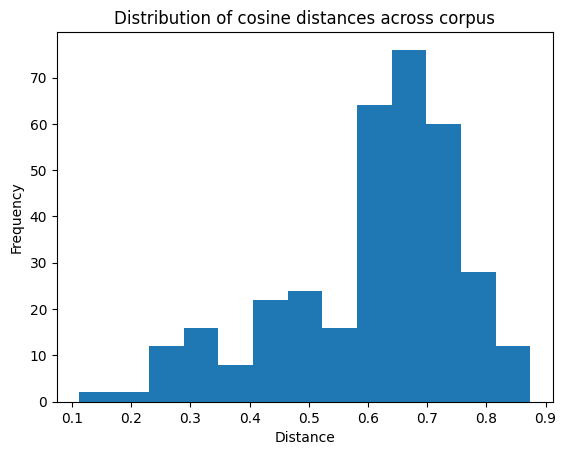


Smallest distance (most similar): 0.1123
  WHom_SermoLupi_A ↔ WHom_SermoLupi_B

Largest distance (most different): 0.8744
  WHom_SermoLupi_B ↔ BlHom_VII


In [12]:
# Histogram of distance scores + most/least similar pairs
matrix = distance_calculator(counts, "cosine", corpus_metadata.index)

arr = matrix.values
arr_no_diag = arr[~np.eye(arr.shape[0], dtype=bool)]
arr_no_diag = arr_no_diag.flatten()
arr_no_diag.sort()

import matplotlib.pyplot as plt
plt.hist(arr_no_diag, bins=13)
plt.title("Distribution of cosine distances across corpus")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.show()

min_value = arr_no_diag[0]
min_location = (matrix == min_value)
row_idx, col_name = min_location.stack().idxmax()
print(f"\nSmallest distance (most similar): {min_value:.4f}\n  {row_idx} ↔ {col_name}")

max_value = arr_no_diag[-1]
max_location = (matrix == max_value)
row_idx, col_name = max_location.stack().idxmax()
print(f"\nLargest distance (most different): {max_value:.4f}\n  {row_idx} ↔ {col_name}")

In [13]:
# reduce matrix dimensions
reduced_tsne = reduce_dimensions_tsne(matrix, perplexity=matrix.shape[0]**0.5, n_iter=5000, metric="euclidean", metadata=corpus_metadata)

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning:

'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.



In [14]:
# visualize reduced dimensions

# adjust size column for visualization
size_min = 3
size_max = 70
size = (reduced_tsne["partial_length"] / reduced_tsne["partial_length"].max() * (size_max - size_min) + size_min).tolist()

# Label patch — relabel now that Scragg framing is dropped from the paper
reduced_tsne.loc["VHom_IV", "corpus_manual"] = "Anonymous_Vercelli"
reduced_tsne.loc["BHH_CCCC303", "corpus_manual"] = "Anonymous_Other"

# create figure
fig = px.scatter(reduced_tsne,
                 x="component 1", y="component 2",
                 size=size,
                 symbol="corpus_manual",
                 symbol_map={
                     "Wulfstan": "circle",
                     "Anonymous_Blickling": "diamond",
                     "Anonymous_Vercelli": "square",
                     "Anonymous_Other": "x",
                     "Aelfric": "circle"
                 },
                 color="author_group",
                 hover_data=["partial_length", "full_length", reduced_tsne.index])
fig.update_traces(marker=dict(line=dict(width=1, color='black')))
fig.show()

In [15]:
# ── WORULDENDE: Whole-text TF-IDF with expanded vocabulary (max_features=300) ─────────────────
# Robustness check on LEMMATISED text — result locked to CSV so it's reproducible forever

vectorizer_v2 = TfidfVectorizer(
    input="content",
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b",
    max_features=300,
    stop_words=oe_stopwords
)

counts_v2 = vectorizer_v2.fit_transform(corpus_metadata["text"].tolist()).toarray()
vocab_v2 = vectorizer_v2.vocabulary_
switched_vocab_v2 = {v: k for k, v in vocab_v2.items()}
column_names_v2 = [switched_vocab_v2[x] for x in range(len(switched_vocab_v2))]
counts_df_v2 = pd.DataFrame(counts_v2, index=corpus_metadata.index, columns=column_names_v2)

print(f"\nVocabulary size (v2): {len(column_names_v2)} words")

# Distance matrix and t-SNE
matrix_v2 = distance_calculator(counts_v2, "cosine", corpus_metadata.index)

reduced_tsne_v2 = reduce_dimensions_tsne(matrix_v2,
                                          perplexity=matrix_v2.shape[0]**0.5,
                                          n_iter=5000,
                                          metric="euclidean",
                                          metadata=corpus_metadata)

# Label patch — relabel now that Scragg framing is dropped from the paper
reduced_tsne_v2.loc["VHom_IV", "corpus_manual"] = "Anonymous_Vercelli"
reduced_tsne_v2.loc["BHH_CCCC303", "corpus_manual"] = "Anonymous_Other"

# Lock this result in permanently, so it can never silently change again
reduced_tsne_v2.to_csv("Woruldende_wholetext_300_FINAL.csv")

# Visualise
fig_v2_wholetext = px.scatter(reduced_tsne_v2,
                 x="component 1", y="component 2",
                 color="author_group",
                 symbol="corpus_manual",
                 symbol_map={
                     "Wulfstan": "circle",
                     "Anonymous_Blickling": "diamond",
                     "Anonymous_Vercelli": "square",
                     "Anonymous_Other": "x",
                     "Aelfric": "circle"
                 },
                 hover_data=["corpus_manual", reduced_tsne_v2.index],
                 title="t-SNE: Whole-text Corpus, lemmatised (max_features=300)",
                 color_discrete_map={
                     "Wulfstan": "#636efa",
                     "Anonymous": "#EF553B",
                     "Aelfric": "#00cc96"
                 },
                 height=700)
fig_v2_wholetext.update_xaxes(title_text="t-SNE dimension 1")
fig_v2_wholetext.update_yaxes(title_text="t-SNE dimension 2")

fig_v2_wholetext.update_traces(marker=dict(size=10, line=dict(width=1, color='black')))
fig_v2_wholetext.show()

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning:

'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.




Vocabulary size (v2): 300 words


In [16]:
fig_v2_wholetext.update_layout(
    paper_bgcolor='white',
    plot_bgcolor='white',
    font=dict(size=16),
    legend=dict(font=dict(size=14)),
    xaxis=dict(title_font=dict(size=16), tickfont=dict(size=14)),
    yaxis=dict(title_font=dict(size=16), tickfont=dict(size=14))
)
fig_v2_wholetext.show()

In [17]:
def find_shared_tokens(df, text_ids):

  mini_df = df[df.index.isin(text_ids)].copy()
  mini_df = mini_df.loc[:, (mini_df != 0).all(axis=0)].copy()
  return mini_df.transpose()

In [18]:
shared_tokens = find_shared_tokens(counts_df, ["BlHom_VII", "BlHom_X", "BlHom_XI", "VHom_II", "VHom_IV"])

In [19]:
# ── COMBINED AUTHOR COMPARISON CHART ─────────────────────────
# Shows distinctive vocabulary for all three author groups side by side

from scipy.stats import zscore

# Get one representative text per group for comparison
# Use the full group TF-IDF scores averaged across texts

# Define groups
groups = {
    "Wulfstan": ["WHom_SermoLupi_A", "WHom_SermoLupi_B", "WHom_Antichrist", "WHom_SignsDoom"],
    "Anonymous": ["BlHom_II", "BlHom_IV", "BlHom_V", "BlHom_VII", "BlHom_X", "BlHom_XI",
                  "VHom_II", "VHom_IV", "VHom_V", "VHom_IX", "BHH_CCCC303"],
    "Aelfric": ["AECHom_I", "AECHom_XV", "AECHom_XXI", "AECHom_XL"]
}

# Calculate mean TF-IDF score per group
group_means = {}
for group_name, text_ids in groups.items():
    group_df = counts_df[counts_df.index.isin(text_ids)]
    group_means[group_name] = group_df.mean(axis=0)

# Build comparison dataframe
comparison_df = pd.DataFrame(group_means)

# For each group, find its TOP 10 most distinctive words
# (highest score in that group relative to the others)
top_words = set()
for group in groups.keys():
    other_groups = [g for g in groups.keys() if g != group]
    # Distinctiveness = this group's score minus mean of other groups
    distinctiveness = comparison_df[group] - comparison_df[other_groups].mean(axis=1)
    top_10 = distinctiveness.nlargest(10).index.tolist()
    top_words.update(top_10)

# Filter comparison to just these distinctive words
plot_df = comparison_df.loc[list(top_words)].reset_index()
plot_df.columns = ["word", "Wulfstan", "Anonymous", "Aelfric"]

# Melt for plotting
plot_melted = plot_df.melt(id_vars="word", var_name="author_group", value_name="tfidf_score")

# Plot
fig = px.bar(plot_melted,
             x="word",
             y="tfidf_score",
             color="author_group",
             barmode="group",
             title="Distinctive Vocabulary by Author Group",
             labels={"word": "Word", "tfidf_score": "Mean TF-IDF Score", "author_group": "Author Group"},
             color_discrete_map={"Wulfstan": "#636efa", "Anonymous": "#EF553B", "Aelfric": "#00cc96"},
             height=600,
             width=1400)

fig.update_layout(
    xaxis_tickangle=-45,
    font=dict(size=12),
    legend=dict(orientation="h", yanchor="bottom", y=1.02)
)
fig.show()

In [20]:
# ── ALL THREE GROUPS SHARED TOKENS ON ONE CHART ──────────────

# Find words shared within each group
wulfstan_shared = find_shared_tokens(counts_df,
    ["WHom_SermoLupi_A", "WHom_SermoLupi_B", "WHom_Antichrist", "WHom_SignsDoom"])

anonymous_shared = find_shared_tokens(counts_df,
    ["BlHom_VII", "BlHom_X", "BlHom_XI", "VHom_II", "VHom_IV", "VHom_V", "VHom_IX", "BHH_CCCC303", "BlHom_II", "BlHom_IV", "BlHom_V"])

aelfric_shared = find_shared_tokens(counts_df,
    ["AECHom_I", "AECHom_XV", "AECHom_XXI", "AECHom_XL"])

# Get mean score per group for their shared words
wulfstan_mean = wulfstan_shared.mean(axis=1).rename("Wulfstan")
anonymous_mean = anonymous_shared.mean(axis=1).rename("Anonymous")
aelfric_mean = aelfric_shared.mean(axis=1).rename("Aelfric")

# Combine — keep only words that appear in at least one group's shared set
combined = pd.concat([wulfstan_mean, anonymous_mean, aelfric_mean], axis=1).fillna(0)

# Sort by total score so most important words appear first
combined["total"] = combined.sum(axis=1)
combined = combined.sort_values("total", ascending=False).drop(columns="total")
combined = combined.head(30)  # top 30 words

# Melt for plotting
combined_melted = combined.reset_index().melt(
    id_vars="index", var_name="Author Group", value_name="Mean TF-IDF Score")

# Plot
fig = px.bar(combined_melted,
             x="index",
             y="Mean TF-IDF Score",
             color="Author Group",
             barmode="group",
             title="Shared Vocabulary Compared Across All Three Author Groups",
             labels={"index": "Word"},
             color_discrete_map={"Wulfstan": "#636efa", "Anonymous": "#EF553B", "Aelfric": "#00cc96"},
             height=600,
             width=1400)

fig.update_layout(
    xaxis_tickangle=-45,
    font=dict(size=12),
    legend=dict(orientation="h", yanchor="bottom", y=1.02)
)
fig.show()

In [21]:
# ── SHARED TOKENS SCATTER WITH LABELS ────────────────────────
fig = px.scatter(shared_tokens,
                 title="Shared Vocabulary Across Author Group",
                 height=500,
                 width=1200)

# Add word labels to every dot
fig.update_traces(
    mode="markers+text",
    textposition="top center",
    textfont=dict(size=10)
)

fig.update_layout(
    xaxis_tickangle=-45,
    margin=dict(b=100)
)
fig.show()

In [22]:
# ── WORULDENDE: Generate chunks directly in Colab use instead of downloaded files ─────────────────
# UPDATED: now uses lemmatised (cf) text with fallback to unicode, matching the whole-text cell
# UPDATED AGAIN: normalises dryhten → drihten (Vercelli spelling variant)
import re, pandas as pd

def chunk_text(text, text_id, author_group, corpus_manual, chunk_size=500):
    words = [w for w in text.split() if w.strip()]
    chunks = []
    chunk_num = 1
    for i in range(0, len(words), chunk_size):
        chunk_words = words[i:i+chunk_size]
        if len(chunk_words) >= 200:
            chunks.append({
                'chunk_id': f"{text_id}_chunk{chunk_num}",
                'parent_text': text_id,
                'chunk_num': chunk_num,
                'author_group': author_group,
                'corpus_manual': corpus_manual,
                'language_manual': 'Old English',
                'text': ' '.join(chunk_words),
                'word_count': len(chunk_words)
            })
            chunk_num += 1
    return chunks

# Build chunks directly from corpus (already loaded in memory)
all_chunks = []
for df in corpus:
    text_id = df["text"].iloc[0]
    meta_row = metadata.loc[text_id] if text_id in metadata.index else None
    if meta_row is None:
        continue
    author_group = meta_row["author_group"]
    corpus_manual = meta_row["corpus_manual"]

    # Get full text using lemma (cf) where available, otherwise fall back to unicode
    words = []
    for _, row in df.iterrows():
        cf = str(row.get("cf", "")).strip()
        unicode_word = str(row.get("unicode", "")).strip()
        if cf and cf not in ["", "X", "nan", "UNK"]:
            cf_clean = "drihten" if cf.lower() == "dryhten" else cf.lower()
            words.append(cf_clean)
        elif unicode_word and unicode_word not in ["", "X", "nan"]:
            uw_clean = "drihten" if unicode_word.lower() == "dryhten" else unicode_word.lower()
            words.append(uw_clean)
    text = " ".join(words)

    chunks = chunk_text(text, text_id, author_group, corpus_manual)
    all_chunks.extend(chunks)
    print(f"✓ {text_id}: {len(chunks)} chunks")

chunks_df = pd.DataFrame(all_chunks)
chunks_meta = pd.DataFrame([{
    'text_id': c['chunk_id'],
    'author_group': c['author_group'],
    'corpus_manual': c['corpus_manual'],
    'language_manual': c['language_manual'],
    'parent_text': c['parent_text'],
    'chunk_num': c['chunk_num'],
    'word_count': c['word_count']
} for c in all_chunks]).set_index('text_id')

print(f"\nTotal chunks: {len(all_chunks)}")
print(chunks_meta["author_group"].value_counts())

# Vectorize
chunk_vectorizer = TfidfVectorizer(
    input="content",
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b",
    max_features=100,
    stop_words=oe_stopwords
)

chunk_counts = chunk_vectorizer.fit_transform(
    chunks_df["text"].tolist()).toarray()
chunk_vocab = chunk_vectorizer.vocabulary_
chunk_switched = {v: k for k, v in chunk_vocab.items()}
chunk_cols = [chunk_switched[x] for x in range(len(chunk_switched))]
chunk_counts_df = pd.DataFrame(chunk_counts,
                                index=chunks_df["chunk_id"].tolist(),
                                columns=chunk_cols)

print(f"✓ Vectorized: {chunk_counts.shape[0]} chunks, {chunk_counts.shape[1]} features")

# Distance matrix and t-SNE
chunk_matrix = distance_calculator(chunk_counts, "cosine", chunk_counts_df.index)

reduced_chunks = reduce_dimensions_tsne(chunk_matrix,
                                         perplexity=chunk_matrix.shape[0]**0.5,
                                         n_iter=5000,
                                         metric="euclidean",
                                         metadata=chunks_meta)

# Label patch — relabel now that Scragg framing is dropped from the paper
chunk_mask_vhomiv = reduced_chunks["parent_text"] == "VHom_IV"
chunk_mask_bhh = reduced_chunks["parent_text"] == "BHH_CCCC303"
reduced_chunks.loc[chunk_mask_vhomiv, "corpus_manual"] = "Anonymous_Vercelli"
reduced_chunks.loc[chunk_mask_bhh, "corpus_manual"] = "Anonymous_Other"

# Visualise
fig = px.scatter(reduced_chunks,
                 x="component 1", y="component 2",
                 color="author_group",
                 symbol="corpus_manual",
                 symbol_map={
                     "Wulfstan": "circle",
                     "Anonymous_Blickling": "diamond",
                     "Anonymous_Vercelli": "square",
                     "Anonymous_Other": "x",
                     "Aelfric": "circle"
                 },
                 hover_data=["parent_text", "chunk_num", reduced_chunks.index],
                 title="t-SNE: 500-word Chunks Across All Texts (lemmatised)",
                 color_discrete_map={
                     "Wulfstan": "#636efa",
                     "Anonymous": "#EF553B",
                     "Aelfric": "#00cc96"
                 },
                 height=700)

fig.update_traces(marker=dict(size=10, line=dict(width=1, color='black')))
fig.show()

✓ WHom_SermoLupi_A: 4 chunks
✓ WHom_SermoLupi_B: 4 chunks
✓ WHom_Antichrist: 1 chunks
✓ WHom_SignsDoom: 2 chunks
✓ BlHom_II: 4 chunks
✓ BlHom_IV: 6 chunks
✓ BlHom_V: 4 chunks
✓ BlHom_VII: 5 chunks
✓ BlHom_X: 3 chunks
✓ BlHom_XI: 6 chunks
✓ VHom_II: 3 chunks
✓ VHom_IV: 8 chunks
✓ VHom_V: 4 chunks
✓ VHom_IX: 4 chunks
✓ BHH_CCCC303: 2 chunks
✓ AECHom_I: 6 chunks
✓ AECHom_XV: 3 chunks
✓ AECHom_XXI: 5 chunks
✓ AECHom_XL: 3 chunks

Total chunks: 77
author_group
Anonymous    49
Aelfric      17
Wulfstan     11
Name: count, dtype: int64
✓ Vectorized: 77 chunks, 100 features


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning:

'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.



In [23]:
# ── WORULDENDE: Chunk-level t-SNE with expanded vocabulary (max_features=300) max_features=300 robustness check ─────────────────
# Tests whether the upper-cluster convergence (Sophonias/dæg/helle chunks) survives
# with a less restrictive TF-IDF feature cap, or whether it was a max_features=100 artifact

chunk_vectorizer_v2 = TfidfVectorizer(
    input="content",
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b",
    max_features=300,
    stop_words=oe_stopwords
)

chunk_counts_v2 = chunk_vectorizer_v2.fit_transform(
    chunks_df["text"].tolist()).toarray()
chunk_vocab_v2 = chunk_vectorizer_v2.vocabulary_
chunk_switched_v2 = {v: k for k, v in chunk_vocab_v2.items()}
chunk_cols_v2 = [chunk_switched_v2[x] for x in range(len(chunk_switched_v2))]
chunk_counts_df_v2 = pd.DataFrame(chunk_counts_v2,
                                index=chunks_df["chunk_id"].tolist(),
                                columns=chunk_cols_v2)

print(f"✓ Vectorized (v2, max_features=300): {chunk_counts_v2.shape[0]} chunks, {chunk_counts_v2.shape[1]} features")

# Distance matrix and t-SNE
chunk_matrix_v2 = distance_calculator(chunk_counts_v2, "cosine", chunk_counts_df_v2.index)

reduced_chunks_v2 = reduce_dimensions_tsne(chunk_matrix_v2,
                                         perplexity=chunk_matrix_v2.shape[0]**0.5,
                                         n_iter=5000,
                                         metric="euclidean",
                                         metadata=chunks_meta)

# Label patch — relabel now that Scragg framing is dropped from the paper
chunk_mask_vhomiv = reduced_chunks_v2["parent_text"] == "VHom_IV"
chunk_mask_bhh = reduced_chunks_v2["parent_text"] == "BHH_CCCC303"
reduced_chunks_v2.loc[chunk_mask_vhomiv, "corpus_manual"] = "Anonymous_Vercelli"
reduced_chunks_v2.loc[chunk_mask_bhh, "corpus_manual"] = "Anonymous_Other"

print(reduced_chunks_v2[reduced_chunks_v2["parent_text"] == "VHom_V"][["component 1", "component 2"]])

# Visualise
fig_v2_chunks = px.scatter(reduced_chunks_v2,
                 x="component 1", y="component 2",
                 color="author_group",
                 symbol="corpus_manual",
                 symbol_map={
                     "Wulfstan": "circle",
                     "Anonymous_Blickling": "diamond",
                     "Anonymous_Vercelli": "square",
                     "Anonymous_Other": "x",
                     "Aelfric": "circle"
                 },
                 hover_data=["parent_text", "chunk_num", reduced_chunks_v2.index],
                 title="t-SNE: 500-word Chunks (max_features=300)",
                 color_discrete_map={
                     "Wulfstan": "#636efa",
                     "Anonymous": "#EF553B",
                     "Aelfric": "#00cc96"
                 },
                 height=700)

fig_v2_chunks.update_traces(marker=dict(size=10, line=dict(width=1, color='black')))

fig_v2_chunks.update_xaxes(title_text="t-SNE dimension 1")
fig_v2_chunks.update_yaxes(title_text="t-SNE dimension 2")

fig_v2_chunks.add_annotation( x=-43.76, y=-36.35, text="VHom_V", showarrow=True, arrowhead=2, arrowsize=1, arrowwidth=1.5, ax=40, ay=-40, font=dict(size=14) )

fig_v2_chunks.show()



/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning:

'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.



✓ Vectorized (v2, max_features=300): 77 chunks, 300 features
               component 1  component 2
text_id                                
VHom_V_chunk1    -1.136975     0.307124
VHom_V_chunk2    -4.001186    -1.308299
VHom_V_chunk3    -2.453030    -0.865318
VHom_V_chunk4    -0.147872    -0.824989


In [24]:
fig_v2_chunks.update_layout(
    paper_bgcolor='white',
    plot_bgcolor='white',
    font=dict(size=16),
    legend=dict(font=dict(size=14)),
    xaxis=dict(title_font=dict(size=16), tickfont=dict(size=14)),
    yaxis=dict(title_font=dict(size=16), tickfont=dict(size=14))
)
fig_v2_chunks.show()

In [25]:
chunk_ids_to_check = [
    "AECHom_XL_chunk3", "AECHom_I_chunk6",
    "BHH_CCCC303_chunk2", "VHom_II_chunk1",
    "VHom_IV_chunk4", "VHom_IV_chunk5", "VHom_IV_chunk7"
]

for cid in chunk_ids_to_check:
    row = chunks_df[chunks_df["chunk_id"] == cid]
    if not row.empty:
        print(f"\n=== {cid} ===")
        print(row["text"].values[0])
    else:
        print(f"\n=== {cid} NOT FOUND — check exact id/column name ===")


=== AECHom_XL_chunk3 ===
drihten to iudeiscre mægðe and heora cynn ne gewít þurh ateorunge ærðan ðe þes middangeard geendað be ðisum andgite cwæð se apostol paulus þæt drihten sylf astihð of heofon on stemne þæs heahengles and mid god byme and ða deadan ærest arisan syððan we ðe lybbað and on lichaman beoð gemette beoð gelæhte forð mid þam oðrum on wolcnum togeanes criste and we swa symle syððan mid god beoð frefriað eów mid þisum wordum eac on ðisum andgite geðwærlæhð se godspellere matheus þisum wordum drihten asent his englas mid byme and micelre stemne and hí gaderiað his gecorenan fram feower windum of eallum eorðlicum gemærum oð ða heálican heofonan se apostol cwæð we ðe lybbað ne mænde he hine sylfne mid þam worde ac ða ðe on life þurhwuniað oþ geendunge þyssere woruld mid þam is eac geswutelod þæt mancynn mid ealle ne ateorað ær ðære geendunge ac hí habbað hwæðere sceortne deaþ þa ðe þonne on life gemette beoð forðan ðe heofonlic fȳr ofergæð ealne middangeard mid anum bryne an

In [26]:
for cid in ["AECHom_XL_chunk3", "BHH_CCCC303_chunk2", "VHom_IX_chunk4", "VHom_II_chunk2"]:
    print(f"\n=== {cid} top TF-IDF terms ===")
    row = chunk_counts_df.loc[cid]
    print(row.sort_values(ascending=False).head(15))


=== AECHom_XL_chunk3 top TF-IDF terms ===
dæg            0.663597
cwæð           0.356021
heofon         0.257894
eorþe          0.253861
fram           0.196533
god            0.185977
mine           0.184979
drihten        0.159506
symle          0.159001
buton          0.142408
seo            0.121201
middangeard    0.112566
eac            0.110957
cristes        0.094800
heo            0.088274
Name: AECHom_XL_chunk3, dtype: float64

=== BHH_CCCC303_chunk2 top TF-IDF terms ===
dæg        0.855719
butan      0.219595
heofon     0.174593
synn       0.169207
hæfde      0.146397
hell       0.138137
lif        0.124237
magon      0.122186
ende       0.111082
drihten    0.095986
woruld     0.088376
naman      0.076278
a          0.073198
habban     0.071762
wið        0.067801
Name: BHH_CCCC303_chunk2, dtype: float64

=== VHom_IX_chunk4 top TF-IDF terms ===
butan     0.515524
rice      0.401936
sy        0.354090
sio       0.265015
mycel     0.208473
ofer      0.200968
deofol    0.18440

In [27]:
# ── WORULDENDE: Five-way comparison — splitting Anonymous into Blickling vs Vercelli ─────────────────
# Ad-hoc follow-up: does Blickling actually differ from Vercelli in vocabulary,
# or just in t-SNE position? Reuses the final lemmatised, max_features=300 whole-text result.

five_groups = {
    "Wulfstan": ["WHom_SermoLupi_A", "WHom_SermoLupi_B", "WHom_Antichrist", "WHom_SignsDoom"],
    "Blickling": ["BlHom_II", "BlHom_IV", "BlHom_V", "BlHom_VII", "BlHom_X", "BlHom_XI"],
    "Vercelli": ["VHom_II", "VHom_IV", "VHom_V", "VHom_IX"],
    "Other_anonymous": ["BHH_CCCC303"],   # single text — shown for completeness, not statistically meaningful alone
    "Aelfric": ["AECHom_I", "AECHom_XV", "AECHom_XXI", "AECHom_XL"]
}

# Mean TF-IDF score per group
five_group_means = {}
for group_name, text_ids in five_groups.items():
    group_df = counts_df_v2[counts_df_v2.index.isin(text_ids)]
    five_group_means[group_name] = group_df.mean(axis=0)

five_comparison_df = pd.DataFrame(five_group_means)

# Top 8 most distinctive words per group
five_top_words = set()
for group in five_groups.keys():
    other_groups = [g for g in five_groups.keys() if g != group]
    distinctiveness = five_comparison_df[group] - five_comparison_df[other_groups].mean(axis=1)
    five_top_words.update(distinctiveness.nlargest(8).index.tolist())

five_plot_df = five_comparison_df.loc[list(five_top_words)].reset_index()
five_plot_df.columns = ["word", "Wulfstan", "Blickling", "Vercelli", "Other_anonymous", "Aelfric"]
five_plot_melted = five_plot_df.melt(id_vars="word", var_name="group", value_name="tfidf_score")

fig_five = px.bar(five_plot_melted,
             x="word", y="tfidf_score", color="group", barmode="group",
             title="Distinctive Vocabulary: Blickling vs Vercelli (Wulfstan/Aelfric shown for reference)",
             labels={"word": "Word", "tfidf_score": "Mean TF-IDF Score", "group": "Group"},
             color_discrete_map={
                 "Wulfstan": "#636efa",
                 "Blickling": "#EF553B",
                 "Vercelli": "#FFA15A",
                 "Other_anonymous": "#AB63FA",
                 "Aelfric": "#00cc96"
             },
             height=600, width=1400)

fig_five.update_layout(xaxis_tickangle=-45, font=dict(size=12),
                        legend=dict(orientation="h", yanchor="bottom", y=1.02))
fig_five.show()

# Direct numeric check — does this confirm Vercelli sits closer to everyone else?
from scipy.spatial.distance import cosine

print(f"Blickling vs Vercelli: {cosine(five_comparison_df['Blickling'], five_comparison_df['Vercelli']):.4f}")
print(f"Blickling vs Wulfstan: {cosine(five_comparison_df['Blickling'], five_comparison_df['Wulfstan']):.4f}")
print(f"Blickling vs Aelfric:  {cosine(five_comparison_df['Blickling'], five_comparison_df['Aelfric']):.4f}")
print(f"Vercelli vs Wulfstan:  {cosine(five_comparison_df['Vercelli'], five_comparison_df['Wulfstan']):.4f}")
print(f"Vercelli vs Aelfric:   {cosine(five_comparison_df['Vercelli'], five_comparison_df['Aelfric']):.4f}")

Blickling vs Vercelli: 0.5430
Blickling vs Wulfstan: 0.6365
Blickling vs Aelfric:  0.5925
Vercelli vs Wulfstan:  0.6236
Vercelli vs Aelfric:   0.4724


In [28]:
mean_distances = matrix_v2.mean(axis=1).sort_values(ascending=False)
print(mean_distances)

text_id
AECHom_XV           0.727196
WHom_SermoLupi_B    0.724871
BHH_CCCC303         0.708075
WHom_Antichrist     0.690479
VHom_IX             0.680245
WHom_SermoLupi_A    0.672507
AECHom_XL           0.649851
VHom_IV             0.647384
VHom_II             0.644166
WHom_SignsDoom      0.642157
VHom_V              0.636699
BlHom_VII           0.631694
BlHom_II            0.621751
AECHom_XXI          0.621318
BlHom_V             0.617401
AECHom_I            0.613748
BlHom_XI            0.613739
BlHom_X             0.613279
BlHom_IV            0.600496
dtype: float64


In [29]:
mean_distance_outside_group = {}
for text_id in corpus_metadata.index:
    own_group = corpus_metadata.loc[text_id, "author_group"]
    other_texts = corpus_metadata[corpus_metadata["author_group"] != own_group].index
    mean_distance_outside_group[text_id] = matrix_v2.loc[text_id, other_texts].mean()

result = pd.Series(mean_distance_outside_group).sort_values(ascending=False)
print(result)

# Also show group-level averages
group_avg = result.groupby(corpus_metadata["author_group"]).mean()
print("\nMean distance-to-other-groups, by group:")
print(group_avg.sort_values(ascending=False))

WHom_SermoLupi_B    0.816499
AECHom_XV           0.809371
BlHom_VII           0.798114
BlHom_II            0.779127
VHom_IX             0.775180
BlHom_V             0.772311
WHom_SermoLupi_A    0.767853
BHH_CCCC303         0.765455
WHom_Antichrist     0.754032
BlHom_XI            0.749083
VHom_II             0.739279
BlHom_IV            0.725459
VHom_IV             0.716296
AECHom_XL           0.715628
WHom_SignsDoom      0.712903
BlHom_X             0.702076
AECHom_XXI          0.697918
VHom_V              0.678872
AECHom_I            0.670666
dtype: float64

Mean distance-to-other-groups, by group:
author_group
Wulfstan     0.762822
Anonymous    0.745568
Aelfric      0.723396
dtype: float64


In [30]:
print(counts_df_v2.loc[:, "heofon"] if "heofon" in counts_df_v2.columns else "not in vocab")

text_id
WHom_SermoLupi_A    0.000000
WHom_SermoLupi_B    0.000000
WHom_Antichrist     0.054030
WHom_SignsDoom      0.038397
BlHom_VII           0.088173
BlHom_X             0.020736
BlHom_XI            0.092764
BlHom_II            0.000000
BlHom_IV            0.039154
BlHom_V             0.000000
VHom_II             0.095590
VHom_IV             0.032962
VHom_V              0.118663
VHom_IX             0.012848
BHH_CCCC303         0.130727
AECHom_I            0.023755
AECHom_XV           0.085459
AECHom_XXI          0.136720
AECHom_XL           0.076658
Name: heofon, dtype: float64


In [ ]:
# ── WORULDENDE: Robustness check — NO stopwords removed ─────────
# Tests whether the three-group separation holds without stopword filtering

vectorizer_nostop = TfidfVectorizer(
    input="content",
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b",
    max_features=100,
    stop_words=None  # no stopwords removed
)

counts_nostop = vectorizer_nostop.fit_transform(
    corpus_metadata["text"].tolist()).toarray()
vocab_nostop = vectorizer_nostop.vocabulary_
switched_nostop = {v: k for k, v in vocab_nostop.items()}
column_names_nostop = [switched_nostop[x] for x in range(len(switched_nostop))]
counts_df_nostop = pd.DataFrame(counts_nostop,
    index=corpus_metadata.index, columns=column_names_nostop)

print("Top 20 features without stopword removal:")
print(column_names_nostop[:20])

matrix_nostop = distance_calculator(counts_nostop, "cosine", corpus_metadata.index)

reduced_nostop = reduce_dimensions_tsne(matrix_nostop,
                                         perplexity=matrix_nostop.shape[0]**0.5,
                                         n_iter=5000,
                                         metric="euclidean",
                                         metadata=corpus_metadata)

fig_nostop = px.scatter(reduced_nostop,
                 x="component 1", y="component 2",
                 color="author_group",
                 symbol="corpus_manual",
                 symbol_map={
                     "Wulfstan": "circle",
                     "Anonymous_Blickling": "diamond",
                     "Anonymous_Vercelli": "square",
                     "Anonymous_Other": "x",
                     "Aelfric": "circle"
                 },
                 hover_data=["corpus_manual", reduced_nostop.index],
                 title="t-SNE: No stopwords removed (max_features=100)",
                 color_discrete_map={
                     "Wulfstan": "#636efa",
                     "Anonymous": "#EF553B",
                     "Aelfric": "#00cc96"
                 },
                 height=700)

fig_nostop.update_traces(marker=dict(size=10, line=dict(width=1, color='black')))
fig_nostop.show()

In [31]:
# Save charts using write_html instead
fig_heatmap = px.imshow(matrix)
fig_heatmap.update_layout(autosize=False, width=1500, height=1500)
fig_heatmap.write_html("Woruldende_heatmap_distances.html")

size = (reduced_tsne["partial_length"] / reduced_tsne["partial_length"].max() * (70 - 3) + 3).tolist()
fig_tsne = px.scatter(reduced_tsne, x="component 1", y="component 2", size=size,
                      symbol="corpus_manual", color="author_group",
                      hover_data=["partial_length", "full_length", reduced_tsne.index])
fig_tsne.update_traces(marker=dict(line=dict(width=1, color='black')))
fig_tsne.write_html("Woruldende_tSNE_author_groups.html")

print("Files saved as HTML!")

Files saved as HTML!


## Control analyses and robustness checks

In [32]:
# ============================================================
# Woruldende - lemmatisation diagnostic (one Colab cell, read-only: changes nothing)
# Needs the existing globals: corpus (list of DataFrames), metadata, oe_stopwords
# ============================================================
import collections
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_distances

BLANK = {"", "x", "nan", "unk"}

# ---- 0. Do all CSVs share the same columns? -------------------------------
col_sets = {df["text"].iloc[0]: tuple(df.columns) for df in corpus}
distinct = set(col_sets.values())
print("Distinct column layouts across the 19 CSVs:", len(distinct))
for c in distinct:
    print("  ", c, "->", [t for t, v in col_sets.items() if v == c][:4], "...")

SURF = next((c for c in ("unicode_word", "unicode", "norm") if all(c in df.columns for df in corpus)), None)
print("\nSurface-form column used for this diagnostic:", SURF)
if not all("unicode" in df.columns for df in corpus):
    print("WARNING: the 'complete replacement' cell falls back to a column called 'unicode'. "
          "It is missing in at least one CSV, so tokens with an empty cf would be silently DROPPED there.")

# ---- 1. Per-text lemma coverage -------------------------------------------
rows = []
for df in corpus:
    tid = df["text"].iloc[0]
    cf = df["cf"].astype(str).str.strip().str.lower() if "cf" in df.columns else pd.Series([""] * len(df))
    surf = df[SURF].astype(str).str.strip().str.lower()
    filled, s_ok = ~cf.isin(BLANK), ~surf.isin(BLANK)
    both = filled & s_ok
    rows.append(dict(text=tid, tokens=len(df),
                     cf_filled_pct=round(100 * filled.mean(), 1),
                     cf_equals_surface_pct=round(100 * (cf[both] == surf[both]).mean(), 1) if both.any() else np.nan,
                     surface_types=surf[s_ok].nunique(), lemma_types=cf[filled].nunique()))
cov = pd.DataFrame(rows).set_index("text").join(metadata[["author_group"]])
cov["types_merged_by_cf"] = (cov["surface_types"] / cov["lemma_types"].replace(0, np.nan)).round(2)
print("\n--- per text ---"); print(cov.to_string())
print("\n--- group means (the key table) ---")
print(cov.groupby("author_group")[["cf_filled_pct", "cf_equals_surface_pct", "types_merged_by_cf"]].mean().round(1))

# ---- 2. How are the forms of 'god' handled in each group? -----------------
targets = {"god", "gode", "godes", "godum", "godne"}
print("\n--- surface form -> cf for god-forms, by group ---")
for grp in cov["author_group"].unique():
    ids = set(cov.index[cov["author_group"] == grp])
    sub = pd.concat([df for df in corpus if df["text"].iloc[0] in ids])
    sub = sub.assign(_s=sub[SURF].astype(str).str.lower(), _c=sub["cf"].astype(str).str.lower())
    print(grp, dict(collections.Counter(zip(sub.loc[sub["_s"].isin(targets), "_s"],
                                            sub.loc[sub["_s"].isin(targets), "_c"]))))

# ---- 3. Control: does the grouping survive WITHOUT cf? ---------------------
def build(treatment):
    out = {}
    for df in corpus:
        surf = df[SURF].astype(str).str.strip().str.lower()
        if treatment == "surface":
            toks = surf
        else:
            cf = df["cf"].astype(str).str.strip().str.lower()
            toks = cf.where(~cf.isin(BLANK), surf)
        toks = toks[~toks.isin(BLANK)].replace({"dryhten": "drihten"})  # same manual fix in both
        out[df["text"].iloc[0]] = " ".join(toks)
    return pd.Series(out)

print("\n--- group separation: cf (as in paper) vs surface forms only ---")
for name, texts in {"cf + fallback": build("cf"), "surface forms only": build("surface")}.items():
    labels = metadata.loc[texts.index, "author_group"].values
    for mf in (100, 300):
        X = TfidfVectorizer(lowercase=True, token_pattern=r"(?u)\b\w+\b", max_features=mf,
                            stop_words=oe_stopwords).fit_transform(texts.tolist()).toarray()
        sil = silhouette_score(cosine_distances(X), labels, metric="precomputed")
        gs = sorted(set(labels)); cent = {g: X[labels == g].mean(0) for g in gs}
        pairs = {f"{a}-{b}": round(float(cosine_distances([cent[a]], [cent[b]])[0, 0]), 3)
                 for i, a in enumerate(gs) for b in gs[i + 1:]}
        print(f"{name:20s} max_features={mf:3d}  silhouette={sil:.3f}  centroid distances={pairs}")

Distinct column layouts across the 19 CSVs: 1
   ('token_number', 'ref', 'inst', 'frag', 'norm', 'cf', 'sense', 'pos', 'confidence', 'unicode', 'unicode_word', 'reading', 'break', 'break_perc', 'mask', 'lang', 'author_group', 'text', 'line', 'word') -> ['WHom_SermoLupi_A', 'WHom_SermoLupi_B', 'WHom_Antichrist', 'WHom_SignsDoom'] ...

Surface-form column used for this diagnostic: unicode_word

--- per text ---
                  tokens  cf_filled_pct  cf_equals_surface_pct  surface_types  lemma_types author_group  types_merged_by_cf
text                                                                                                                       
WHom_SermoLupi_A    1738           99.9                   96.8            676          671     Wulfstan                1.01
WHom_SermoLupi_B    2050          100.0                   97.6            771          764     Wulfstan                1.01
WHom_Antichrist      466          100.0                   96.1            253          251 

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.



cf + fallback        max_features=100  silhouette=0.182  centroid distances={'Aelfric-Anonymous': 0.346, 'Aelfric-Wulfstan': 0.45, 'Anonymous-Wulfstan': 0.516}
cf + fallback        max_features=300  silhouette=0.199  centroid distances={'Aelfric-Anonymous': 0.458, 'Aelfric-Wulfstan': 0.571, 'Anonymous-Wulfstan': 0.564}
surface forms only   max_features=100  silhouette=0.203  centroid distances={'Aelfric-Anonymous': 0.441, 'Aelfric-Wulfstan': 0.546, 'Anonymous-Wulfstan': 0.585}
surface forms only   max_features=300  silhouette=0.202  centroid distances={'Aelfric-Anonymous': 0.523, 'Aelfric-Wulfstan': 0.64, 'Anonymous-Wulfstan': 0.621}


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.



In [33]:
# ============================================================
# Woruldende - orthography check (one Colab cell, read-only)
# Question: are the Ælfric texts (Wikisource, Thorpe 1844) spelled differently
# from the ECHOE texts in a way that could drive the clustering?
# Needs the globals: corpus, metadata
# ============================================================
import re, collections
import pandas as pd

BLANK = {"", "x", "nan", "unk"}
rows, freq = [], {}
for df in corpus:
    tid = df["text"].iloc[0]
    toks = [t for t in df["unicode_word"].astype(str).str.strip().str.lower() if t not in BLANK]
    s = " ".join(toks)
    n = len(toks)
    rows.append(dict(text=tid,
                     thorn_per_1000=round(1000 * s.count("þ") / n, 1),
                     eth_per_1000=round(1000 * s.count("ð") / n, 1),
                     eth_share_pct=round(100 * s.count("ð") / max(1, s.count("ð") + s.count("þ")), 1),
                     ae_per_1000=round(1000 * s.count("æ") / n, 1),
                     y_per_1000=round(1000 * s.count("y") / n, 1),
                     ie_per_1000=round(1000 * s.count("ie") / n, 1),
                     non_ascii_letters_other=sum(1 for ch in s if ord(ch) > 127 and ch not in "þðæ ")))
    freq[tid] = collections.Counter(toks)
orth = pd.DataFrame(rows).set_index("text").join(metadata[["author_group"]])
print("--- spelling habits per text ---"); print(orth.to_string())
print("\n--- group means ---")
print(orth.groupby("author_group").mean(numeric_only=True).round(1))

# Words most over-represented in the Aelfric group vs the rest (relative frequency ratio)
def group_counter(g):
    c, n = collections.Counter(), 0
    for tid in metadata.index[metadata["author_group"] == g]:
        c.update(freq[tid]); n += sum(freq[tid].values())
    return c, n
ca, na = group_counter("Aelfric")
cr, nr = collections.Counter(), 0
for g in ("Anonymous", "Wulfstan"):
    c, n = group_counter(g); cr.update(c); nr += n
rows = [(w, ca[w], cr[w], (ca[w] / na) / ((cr[w] + 0.5) / nr)) for w in ca if ca[w] >= 15]
top = sorted(rows, key=lambda r: -r[3])[:30]
print("\n--- 30 words most Aelfric-specific (count>=15): word, Aelfric count, other count, ratio ---")
for w, a, r, x in top:
    print(f"{w:15s} {a:5d} {r:5d} {x:6.1f}")

--- spelling habits per text ---
                  thorn_per_1000  eth_per_1000  eth_share_pct  ae_per_1000  y_per_1000  ie_per_1000  non_ascii_letters_other author_group
text                                                                                                                                     
WHom_SermoLupi_A           113.4         114.0           50.1        116.9        32.8          0.0                        0     Wulfstan
WHom_SermoLupi_B           112.7         114.7           50.4        118.6       110.3          1.5                        0     Wulfstan
WHom_Antichrist            141.6         133.0           48.4        126.6        30.0          2.1                        0     Wulfstan
WHom_SignsDoom             131.0         158.7           54.8        113.8        33.1          0.0                        0     Wulfstan
BlHom_II                   242.0          22.0            8.3        152.6        65.1         13.7                        0    Anonymous
B

In [34]:
# ============================================================
# Woruldende - orthography control (one Colab cell, read-only)
# Question: does the grouping survive when spelling differences between
# editions are removed? (accents stripped, eth -> thorn, in texts AND stopwords)
# Needs the globals: corpus, metadata, oe_stopwords
# ============================================================
import unicodedata, collections
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_distances

BLANK = {"", "x", "nan", "unk"}

def fold(w):
    w = unicodedata.normalize("NFD", w)
    w = "".join(ch for ch in w if not unicodedata.combining(ch))   # i-acute -> i, etc.
    return w.replace("ð", "þ").replace("Ð", "Þ")

def tokens(df, folded):
    cf = df["cf"].astype(str).str.strip().str.lower()
    sf = df["unicode_word"].astype(str).str.strip().str.lower()
    t = cf.where(~cf.isin(BLANK), sf)
    t = t[~t.isin(BLANK)].replace({"dryhten": "drihten"})
    return [fold(x) for x in t] if folded else list(t)

stop_plain = [s for s in oe_stopwords if s not in ("UNK", "X")]
stop_fold = sorted({fold(s) for s in stop_plain})

for name, folded, stops in (("as in paper (accents and eth kept)", False, stop_plain),
                            ("orthography folded", True, stop_fold)):
    texts = pd.Series({df["text"].iloc[0]: " ".join(tokens(df, folded)) for df in corpus})
    labels = metadata.loc[texts.index, "author_group"].values
    for mf in (100, 300):
        X = TfidfVectorizer(lowercase=True, token_pattern=r"(?u)\b\w+\b", max_features=mf,
                            stop_words=stops).fit_transform(texts.tolist()).toarray()
        sil = silhouette_score(cosine_distances(X), labels, metric="precomputed")
        gs = sorted(set(labels)); cent = {g: X[labels == g].mean(0) for g in gs}
        pairs = {f"{a}-{b}": round(float(cosine_distances([cent[a]], [cent[b]])[0, 0]), 3)
                 for i, a in enumerate(gs) for b in gs[i + 1:]}
        print(f"{name:36s} max_features={mf:3d} silhouette={sil:.3f} centroid distances={pairs}")

# Which words are still Aelfric-specific after folding?
freq = {df["text"].iloc[0]: collections.Counter(tokens(df, True)) for df in corpus}
def grp(g):
    c, n = collections.Counter(), 0
    for tid in metadata.index[metadata["author_group"] == g]:
        c.update(freq[tid]); n += sum(freq[tid].values())
    return c, n
ca, na = grp("Aelfric"); cr, nr = collections.Counter(), 0
for g in ("Anonymous", "Wulfstan"):
    c, n = grp(g); cr.update(c); nr += n
rows = [(w, ca[w], cr[w], (ca[w] / na) / ((cr[w] + 0.5) / nr)) for w in ca if ca[w] >= 15 and w not in stop_fold]
print("\n--- top 25 Aelfric-specific words AFTER folding (stopwords removed): word, Aelfric, others, ratio ---")
for w, a, r, x in sorted(rows, key=lambda r: -r[3])[:25]:
    print(f"{w:15s} {a:5d} {r:5d} {x:6.1f}")

as in paper (accents and eth kept)   max_features=100 silhouette=0.182 centroid distances={'Aelfric-Anonymous': 0.346, 'Aelfric-Wulfstan': 0.45, 'Anonymous-Wulfstan': 0.516}
as in paper (accents and eth kept)   max_features=300 silhouette=0.199 centroid distances={'Aelfric-Anonymous': 0.458, 'Aelfric-Wulfstan': 0.571, 'Anonymous-Wulfstan': 0.564}
orthography folded                   max_features=100 silhouette=0.198 centroid distances={'Aelfric-Anonymous': 0.299, 'Aelfric-Wulfstan': 0.491, 'Anonymous-Wulfstan': 0.444}
orthography folded                   max_features=300 silhouette=0.197 centroid distances={'Aelfric-Anonymous': 0.397, 'Aelfric-Wulfstan': 0.588, 'Anonymous-Wulfstan': 0.522}

--- top 25 Aelfric-specific words AFTER folding (stopwords removed): word, Aelfric, others, ratio ---
þaþa               28     0  194.2
seþe               16     0  111.0
adam               18     2   25.0
þisum              23     4   17.7
cristes            23     6   12.3
life               17  

In [43]:
# ===== CELL 4: Heat map of cosine distances (Figure 2 in the paper; max_features=100) =====
import numpy as np, pandas as pd
import plotly.express as px
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_distances

BLANK = {"", "x", "nan", "unk"}

def make_text(df):
    cf = df["cf"].astype(str).str.strip().str.lower()
    sf = df["unicode"].astype(str).str.strip().str.lower()
    t = cf.where(~cf.isin(BLANK), sf)
    t = t[~t.isin(BLANK)].replace({"dryhten": "drihten"})
    return " ".join(t)

texts_all = pd.Series({df["text"].iloc[0]: make_text(df) for df in corpus})
meta_all = metadata.loc[texts_all.index].copy()
meta_all["text"] = texts_all

X = TfidfVectorizer(lowercase=True, token_pattern=r"(?u)\b\w+\b", max_features=100,
                    stop_words=oe_stopwords).fit_transform(meta_all["text"].tolist()).toarray()
names = list(meta_all.index)
dist = pd.DataFrame(cosine_distances(X), index=names, columns=names)

order = meta_all.sort_values(["author_group", "corpus_manual"]).index.tolist()
dist = dist.loc[order, order]

fig_heat = px.imshow(dist.round(2), text_auto=".2f", color_continuous_scale="Blues_r",
                     zmin=0, zmax=1, aspect="equal")
fig_heat.update_traces(textfont_size=9)
fig_heat.update_layout(width=1000, height=1050, paper_bgcolor="white", plot_bgcolor="white",
                       font=dict(size=13), title="Pairwise cosine distances between the 19 texts",
                       coloraxis_colorbar_title="Cosine distance",
                       margin=dict(l=170, r=120, t=80, b=190))
fig_heat.update_xaxes(tickangle=-45)
fig_heat.show()
print("Check: Sermo Lupi A-B =", round(float(dist.loc["WHom_SermoLupi_A", "WHom_SermoLupi_B"]), 3),
      "(paper: 0.11); largest =", round(float(dist.values.max()), 3), "(paper: 0.87)")
try:
    fig_heat.write_image("figure3.png", scale=2)
    print("Saved figure3.png")
except Exception as e:
    print("Could not save automatically:", e)

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.



Check: Sermo Lupi A-B = 0.112 (paper: 0.11); largest = 0.874 (paper: 0.87)
Could not save automatically: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido



In [44]:
# ===== CELL 5: Robustness grid (appendix table) =====
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_distances

BLANK = {"", "x", "nan", "unk"}

def make_text(df):
    cf = df["cf"].astype(str).str.strip().str.lower()
    sf = df["unicode"].astype(str).str.strip().str.lower()
    t = cf.where(~cf.isin(BLANK), sf)
    t = t[~t.isin(BLANK)].replace({"dryhten": "drihten"})
    return " ".join(t)

texts_all = pd.Series({df["text"].iloc[0]: make_text(df) for df in corpus})
meta_all = metadata.loc[texts_all.index].copy()
meta_all["text"] = texts_all

def run(meta, max_features, seeds=(0, 1, 2, 3, 4)):
    vec = TfidfVectorizer(lowercase=True, token_pattern=r"(?u)\b\w+\b",
                          max_features=max_features, stop_words=oe_stopwords)
    X = vec.fit_transform(meta["text"].tolist()).toarray()
    D = cosine_distances(X)
    labels = meta["author_group"].values
    sil = silhouette_score(D, labels, metric="precomputed")
    gs = sorted(set(labels))
    cent = {g: X[labels == g].mean(0) for g in gs}
    cd = {f"{a[:3]}-{b[:3]}": round(float(cosine_distances([cent[a]], [cent[b]])[0, 0]), 2)
          for i, a in enumerate(gs) for b in gs[i + 1:]}
    purities = []
    for s in seeds:
        kw = dict(n_components=2, perplexity=max(2, len(meta) ** 0.5),
                  metric="euclidean", random_state=s, init="random")
        try:
            emb = TSNE(max_iter=5000, **kw).fit_transform(D)
        except TypeError:
            emb = TSNE(n_iter=5000, **kw).fit_transform(D)
        E = np.linalg.norm(emb[:, None] - emb[None], axis=2)
        np.fill_diagonal(E, np.inf)
        purities.append((labels[E.argmin(axis=1)] == labels).mean())
    return dict(n_texts=len(meta), max_features=max_features,
                silhouette=round(sil, 3), centroid_dist=cd,
                nn_purity_mean=round(float(np.mean(purities)), 2),
                nn_purity_min=round(float(np.min(purities)), 2))

rows = []
for mf in (50, 100, 200, 300, 500):
    rows.append({"variant": "all 19 texts", **run(meta_all, mf)})
for mf in (100, 300):
    for drop in ("WHom_SermoLupi_A", "WHom_SermoLupi_B", "VHom_V"):
        rows.append({"variant": f"without {drop}", **run(meta_all.drop(index=drop), mf)})

results = pd.DataFrame(rows)
pd.set_option("display.width", 250, "display.max_colwidth", 80)
print(results.to_string(index=False))
results.to_csv("Woruldende_robustness_grid.csv", index=False)

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:4

                 variant  n_texts  max_features  silhouette                                       centroid_dist  nn_purity_mean  nn_purity_min
            all 19 texts       19            50       0.125 {'Ael-Ano': 0.29, 'Ael-Wul': 0.33, 'Ano-Wul': 0.37}            0.89           0.89
            all 19 texts       19           100       0.182 {'Ael-Ano': 0.35, 'Ael-Wul': 0.45, 'Ano-Wul': 0.52}            0.94           0.89
            all 19 texts       19           200       0.205 {'Ael-Ano': 0.42, 'Ael-Wul': 0.53, 'Ano-Wul': 0.54}            1.00           1.00
            all 19 texts       19           300       0.199 {'Ael-Ano': 0.46, 'Ael-Wul': 0.57, 'Ano-Wul': 0.56}            1.00           1.00
            all 19 texts       19           500       0.190 {'Ael-Ano': 0.49, 'Ael-Wul': 0.61, 'Ano-Wul': 0.59}            1.00           1.00
without WHom_SermoLupi_A       18           100       0.130 {'Ael-Ano': 0.35, 'Ael-Wul': 0.38, 'Ano-Wul': 0.45}            0.93           0.89

*This notebook was created by [Avital Romach](https://github.com/ARomach), with additional code and text by [Eliese-Sophia Lincke](https://www.geschkult.fu-berlin.de/e/aegyptologie/personen/Professorinnen-und-Professoren/Lincke/index.html), [Shai Gordin](https://digitalpasts.github.io/) and [Daniel A. Werning](https://www.bbaw.de/die-akademie/mitarbeiterinnen-mitarbeiter/werning-daniel) in Spring 2024 for the course [Ancient Language Processing](https://digitalpasts.github.io/ALP-course/). Code can be reused under a [CC-BY 4.0](https://creativecommons.org/licenses/by/4.0/)*